# Chapter 19: Stochastic Differential Equations (SDEs)
## Interactive Python & PyTorch Companion Notebook

Welcome to the companion coding notebook for **Chapter 19: Stochastic Differential Equations**. In this notebook, we verify the analytical results from the lecture and exercises through numerical simulation and visualization:

1. **Exercise 1 (Brownian Motion & Quadratic Variation):** Simulating 1D Brownian motion $W_t$, computing discrete $p$-variation sums ($p \in \{1, 2, 3\}$), and verifying $Q_n \to T$ almost surely as $n \to \infty$ with $\mathrm{Var}(Q_n) = 2T^2/n$.
2. **Exercise 2 (Itô SDE & Discretization):** Simulating the Ornstein–Uhlenbeck SDE $dX_t = -\gamma X_t\,dt + \sigma\,dW_t$ via Euler–Maruyama, comparing empirical variances against exact analytical moments, and verifying the discrete variance inflation factor $(1 - \frac{\gamma\eta}{2})^{-1}$.
3. **Exercise 3 (Itô's Lemma & Geometric Brownian Motion):** Applying Itô's lemma to $Y_t = X_t^2$ and Geometric Brownian Motion $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$, demonstrating why the $-\frac{1}{2}\sigma^2 t$ Itô correction causes the median trajectory to decay while the mean grows.
4. **Exercise 4 (From Algorithms to Processes):** Showing that discrete SGD with state-dependent gradient noise covariance $\Sigma(\theta)$ converges weakly in law to the continuous Itô SDE $dX_t = -\nabla f(X_t)\,dt + \sqrt{\eta}\Sigma(X_t)^{1/2}\,dW_t$.
5. **Exercise 5 (Reverse-Time SDE & Score-Based Diffusion):** Deriving and simulating Anderson's Reverse-Time SDE alongside the deterministic Probability Flow ODE on a bimodal Gaussian mixture using exact analytical scores $\nabla_x \log p_t(x)$.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Configure Matplotlib for crisp, publication-quality figures
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")

Environment initialized successfully.


---
## 1. Exercise 1: Brownian Motion & Quadratic Variation

A standard 1D Brownian motion $W_t$ on $[0, T]$ has independent Gaussian increments $\Delta W_k = W_{t_k} - W_{t_{k-1}} \sim \mathcal{N}(0, \Delta t)$ where $\Delta t = T/n$.

### Key Analytical Properties
1. **Covariance:** $\mathrm{Cov}(W_s, W_t) = \min(s, t)$.
2. **Quadratic Variation ($p=2$):** For $Q_n = \sum_{k=1}^n (\Delta W_k)^2$,
   $$\mathbb{E}[Q_n] = n \Delta t = T, \qquad \mathrm{Var}(Q_n) = n \cdot 2(\Delta t)^2 = \frac{2T^2}{n} \xrightarrow{n\to\infty} 0.$$
   Hence $Q_n \to T$ in $L^2(\Omega)$ (and almost surely along dyadic partitions), justifying the formal differential rule $(dW_t)^2 = dt$.
3. **Unbounded Total Variation ($p=1$) & Vanishing Cubic Variation ($p=3$):**
   $$\mathbb{E}\!\left[\sum_{k=1}^n |\Delta W_k|\right] = \sqrt{\frac{2}{\pi}}\,T\sqrt{n} \to \infty, \qquad \mathbb{E}\!\left[\sum_{k=1}^n |\Delta W_k|^3\right] = 2\sqrt{\frac{2}{\pi}}\,\frac{T^{3/2}}{\sqrt{n}} \to 0.$$

Covariance check at s=0.75, t=1.50:
  Empirical Cov(W_s, W_t) = 0.7026 | Exact min(s, t) = 0.7500

At finest partition n = 16384:
  Mean Quadratic Variation E[Q_n] = 2.00034 (Exact T = 2.00000)
  Var(Q_n)                        = 0.000455 (Exact 2T^2/n = 0.000488)


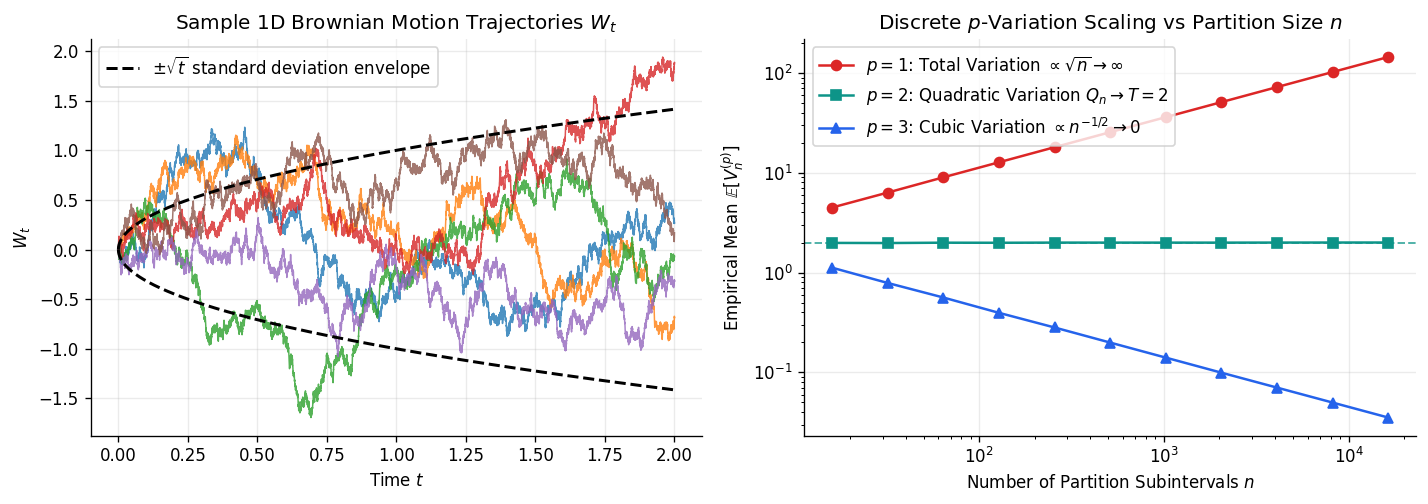

In [2]:
# Simulate Brownian paths and verify p-variation scaling laws
T = 2.0
n_fine = 16384
dt_fine = T / n_fine
n_paths = 1000

# Fine-grid Brownian increments: shape (n_paths, n_fine)
dW_fine = np.sqrt(dt_fine) * np.random.randn(n_paths, n_fine)
W_fine = np.hstack([np.zeros((n_paths, 1)), np.cumsum(dW_fine, axis=1)])
t_grid = np.linspace(0.0, T, n_fine + 1)

# Verify covariance Cov(W_s, W_t) = min(s, t) at s=0.75, t=1.50
idx_s = int(0.75 / dt_fine)
idx_t = int(1.50 / dt_fine)
emp_cov = np.cov(W_fine[:, idx_s], W_fine[:, idx_t])[0, 1]
print(f"Covariance check at s=0.75, t=1.50:")
print(f"  Empirical Cov(W_s, W_t) = {emp_cov:.4f} | Exact min(s, t) = {min(0.75, 1.50):.4f}")

# Dyadic refinement: n = 2^4 to 2^14
dyadic_exponents = np.arange(4, 15)
n_values = 2 ** dyadic_exponents
v1_means, v2_means, v2_vars, v3_means = [], [], [], []

for n_sub in n_values:
    stride = n_fine // n_sub
    W_sub = W_fine[:, ::stride]
    dW_sub = np.diff(W_sub, axis=1)
    
    v1 = np.sum(np.abs(dW_sub), axis=1)
    v2 = np.sum(dW_sub ** 2, axis=1)
    v3 = np.sum(np.abs(dW_sub) ** 3, axis=1)
    
    v1_means.append(np.mean(v1))
    v2_means.append(np.mean(v2))
    v2_vars.append(np.var(v2))
    v3_means.append(np.mean(v3))

print(f"\nAt finest partition n = {n_fine}:")
print(f"  Mean Quadratic Variation E[Q_n] = {v2_means[-1]:.5f} (Exact T = {T:.5f})")
print(f"  Var(Q_n)                        = {v2_vars[-1]:.6f} (Exact 2T^2/n = {2*T**2/n_fine:.6f})")

# Plot sample paths + p-variation convergence
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

for i in range(6):
    axes[0].plot(t_grid, W_fine[i], lw=0.9, alpha=0.8)
axes[0].plot(t_grid, np.sqrt(t_grid), "k--", lw=1.8, label=r"$\pm\sqrt{t}$ standard deviation envelope")
axes[0].plot(t_grid, -np.sqrt(t_grid), "k--", lw=1.8)
axes[0].set_title("Sample 1D Brownian Motion Trajectories $W_t$")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("$W_t$")
axes[0].legend(loc="upper left")

axes[1].loglog(n_values, v1_means, "o-", color="#dc2626", label=r"$p=1$: Total Variation $\propto \sqrt{n} \to \infty$")
axes[1].loglog(n_values, v2_means, "s-", color="#0d9488", label=r"$p=2$: Quadratic Variation $Q_n \to T = 2$")
axes[1].loglog(n_values, v3_means, "^-", color="#2563eb", label=r"$p=3$: Cubic Variation $\propto n^{-1/2} \to 0$")
axes[1].axhline(T, color="#0d9488", ls="--", lw=1.2, alpha=0.7)
axes[1].set_title(r"Discrete $p$-Variation Scaling vs Partition Size $n$")
axes[1].set_xlabel(r"Number of Partition Subintervals $n$")
axes[1].set_ylabel(r"Empirical Mean $\mathbb{E}[V_n^{(p)}]$")
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()

---
## 2. Exercise 2: Itô SDE & Euler–Maruyama Discretization

Consider the 1D **Ornstein–Uhlenbeck (OU)** process:
$$dX_t = -\gamma X_t\,dt + \sigma\,dW_t, \qquad X_0 = x_0, \quad \gamma, \sigma > 0.$$

### Exact Moments vs Discrete Euler–Maruyama
- **Continuous Exact Solution:**
  $$\mathbb{E}[X_t] = x_0 e^{-\gamma t}, \qquad \mathrm{Var}(X_t) = \frac{\sigma^2}{2\gamma}\left(1 - e^{-2\gamma t}\right) \xrightarrow{t\to\infty} v_\infty = \frac{\sigma^2}{2\gamma}.$$
- **Euler–Maruyama Update:** $X_{k+1} = (1 - \gamma\eta)X_k + \sigma\sqrt{\eta}\,\xi_k$.
  - Mean stability requires $|1 - \gamma\eta| < 1 \iff 0 < \eta < \frac{2}{\gamma}$.
  - Discrete stationary variance:
    $$v_\eta = \frac{\sigma^2}{2\gamma\left(1 - \frac{\gamma\eta}{2}\right)} = v_\infty \cdot \left(1 - \frac{\gamma\eta}{2}\right)^{-1} > v_\infty.$$

Continuous Stationary Variance v_inf = 0.4800
  eta = 0.05: Empirical Var = 0.4941 | Exact Discrete v_eta = 0.4987
  eta = 0.42: Empirical Var = 0.6794 | Exact Discrete v_eta = 0.6982
  eta = 0.78: Empirical Var = 1.1695 | Exact Discrete v_eta = 1.1636
  eta = 1.15: Empirical Var = 3.4579 | Exact Discrete v_eta = 3.4909


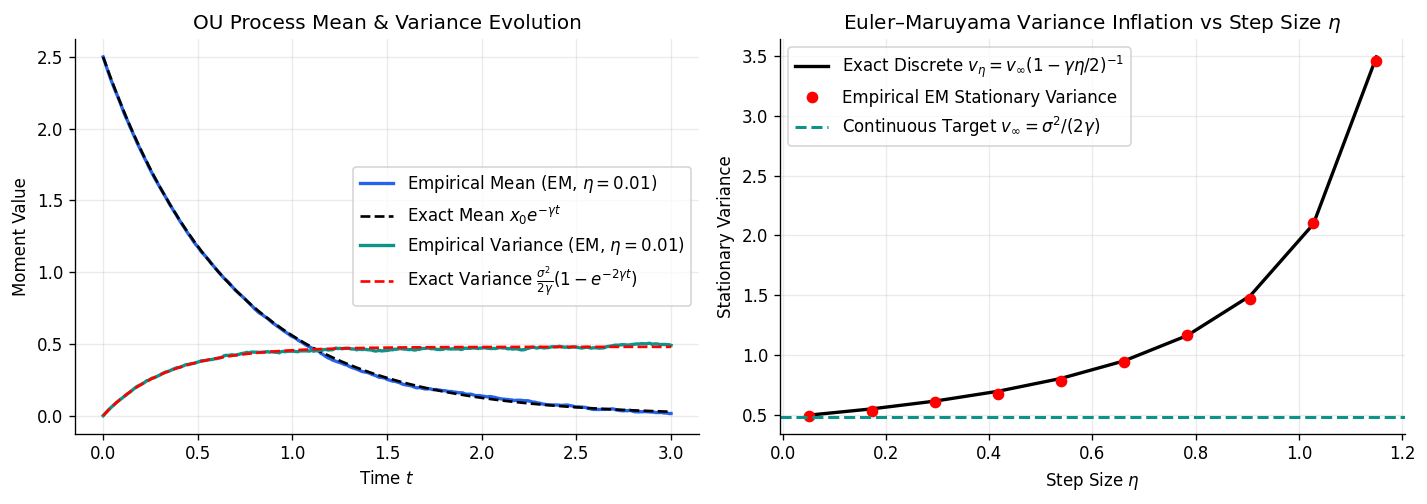

In [3]:
gamma = 1.5
sigma = 1.2
x0 = 2.5
v_inf = (sigma ** 2) / (2.0 * gamma)

# Compare stationary variance across step sizes eta
etas = np.linspace(0.05, 1.15, 10)  # Stability boundary is 2/gamma = 1.333
emp_stationary_vars = []
exact_discrete_vars = [v_inf / (1.0 - 0.5 * gamma * eta) for eta in etas]

n_chains = 4000
for eta in etas:
    n_steps = int(15.0 / eta)
    x = np.full(n_chains, x0, dtype=np.float64)
    for _ in range(n_steps):
        x = (1.0 - gamma * eta) * x + sigma * np.sqrt(eta) * np.random.randn(n_chains)
    emp_stationary_vars.append(np.var(x))

print(f"Continuous Stationary Variance v_inf = {v_inf:.4f}")
for eta, emp_v, th_v in zip(etas[::3], emp_stationary_vars[::3], exact_discrete_vars[::3]):
    print(f"  eta = {eta:.2f}: Empirical Var = {emp_v:.4f} | Exact Discrete v_eta = {th_v:.4f}")

# Time evolution of mean and variance for small vs large step size
t_max = 3.0
eta_small = 0.01
steps_small = int(t_max / eta_small)
t_arr = np.linspace(0, t_max, steps_small + 1)

x_paths = np.zeros((n_chains, steps_small + 1))
x_paths[:, 0] = x0
for k in range(steps_small):
    x_paths[:, k + 1] = (1.0 - gamma * eta_small) * x_paths[:, k] + sigma * np.sqrt(eta_small) * np.random.randn(n_chains)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

axes[0].plot(t_arr, np.mean(x_paths, axis=0), color="#2563eb", lw=2, label="Empirical Mean (EM, $\\eta=0.01$)")
axes[0].plot(t_arr, x0 * np.exp(-gamma * t_arr), "k--", lw=1.6, label=r"Exact Mean $x_0 e^{-\gamma t}$")
axes[0].plot(t_arr, np.var(x_paths, axis=0), color="#0d9488", lw=2, label="Empirical Variance (EM, $\\eta=0.01$)")
axes[0].plot(t_arr, v_inf * (1.0 - np.exp(-2.0 * gamma * t_arr)), "r--", lw=1.6, label=r"Exact Variance $\frac{\sigma^2}{2\gamma}(1 - e^{-2\gamma t})$")
axes[0].set_title("OU Process Mean & Variance Evolution")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("Moment Value")
axes[0].legend(loc="right")

axes[1].plot(etas, exact_discrete_vars, "k-", lw=2, label=r"Exact Discrete $v_\eta = v_\infty(1 - \gamma\eta/2)^{-1}$")
axes[1].plot(etas, emp_stationary_vars, "ro", ms=6, label="Empirical EM Stationary Variance")
axes[1].axhline(v_inf, color="#0d9488", ls="--", lw=1.8, label=r"Continuous Target $v_\infty = \sigma^2/(2\gamma)$")
axes[1].set_title(r"Euler–Maruyama Variance Inflation vs Step Size $\eta$")
axes[1].set_xlabel(r"Step Size $\eta$")
axes[1].set_ylabel("Stationary Variance")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

---
## 3. Exercise 3: Itô's Lemma & Geometric Brownian Motion

For $dX_t = \mu(X_t, t)\,dt + \sigma(X_t, t)\,dW_t$ and smooth $f(x, t)$, **Itô's Lemma** gives:
$$df(X_t, t) = \left(\frac{\partial f}{\partial t} + \mu\frac{\partial f}{\partial x} + \frac{1}{2}\sigma^2\frac{\partial^2 f}{\partial x^2}\right)dt + \sigma\frac{\partial f}{\partial x}\,dW_t.$$

### Geometric Brownian Motion (GBM) Paradox
For $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$, applying Itô's lemma to $f(s) = \ln s$ ($f''(s) = -1/s^2$) yields:
$$d(\ln S_t) = \left(\mu - \frac{1}{2}\sigma^2\right)dt + \sigma\,dW_t \implies S_t = S_0 \exp\!\left(\left(\mu - \frac{1}{2}\sigma^2\right)t + \sigma W_t\right).$$
When $0 < \mu < \frac{1}{2}\sigma^2$:
- The **expected value** grows exponentially: $\mathbb{E}[S_t] = S_0 e^{\mu t} \to \infty$.
- The **median trajectory** decays to zero: $\mathrm{Median}(S_t) = S_0 e^{(\mu - \frac{1}{2}\sigma^2)t} \to 0$.

At terminal time T = 10.0:
  Empirical Mean E[S_T]     = 13.5756 | Exact S0*exp(mu*T)                = 4.4817
  Empirical Median Med(S_T) = 0.1751 | Exact S0*exp((mu - 0.5*sigma^2)T) = 0.1827
  Fraction of paths with S_T < S_0: 75.3%


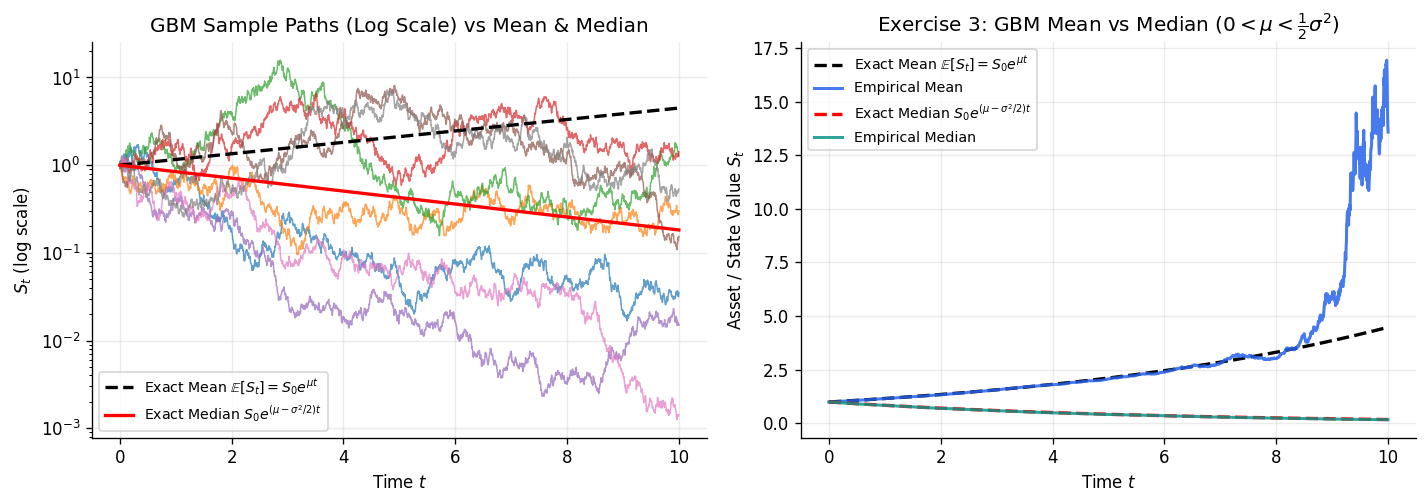

In [4]:
# Simulate GBM in the regime 0 < mu < 0.5 * sigma^2
S0 = 1.0
mu_gbm = 0.15
sigma_gbm = 0.80  # 0.5 * sigma^2 = 0.32 > mu = 0.15
T_gbm = 10.0
n_steps_gbm = 2000
dt_gbm = T_gbm / n_steps_gbm
n_paths_gbm = 20000

t_gbm = np.linspace(0.0, T_gbm, n_steps_gbm + 1)
dW_gbm = np.sqrt(dt_gbm) * np.random.randn(n_paths_gbm, n_steps_gbm)
W_gbm = np.hstack([np.zeros((n_paths_gbm, 1)), np.cumsum(dW_gbm, axis=1)])

# Exact GBM trajectories via Ito's Lemma
S_paths = S0 * np.exp((mu_gbm - 0.5 * sigma_gbm ** 2) * t_gbm[None, :] + sigma_gbm * W_gbm)

emp_mean_S = np.mean(S_paths, axis=0)
emp_median_S = np.median(S_paths, axis=0)
exact_mean_S = S0 * np.exp(mu_gbm * t_gbm)
exact_median_S = S0 * np.exp((mu_gbm - 0.5 * sigma_gbm ** 2) * t_gbm)

print(f"At terminal time T = {T_gbm}:")
print(f"  Empirical Mean E[S_T]     = {emp_mean_S[-1]:.4f} | Exact S0*exp(mu*T)                = {exact_mean_S[-1]:.4f}")
print(f"  Empirical Median Med(S_T) = {emp_median_S[-1]:.4f} | Exact S0*exp((mu - 0.5*sigma^2)T) = {exact_median_S[-1]:.4f}")
print(f"  Fraction of paths with S_T < S_0: {np.mean(S_paths[:, -1] < S0)*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

for i in range(8):
    axes[0].plot(t_gbm, S_paths[i], lw=0.9, alpha=0.7)
axes[0].plot(t_gbm, exact_mean_S, "k--", lw=2.0, label=r"Exact Mean $\mathbb{E}[S_t] = S_0 e^{\mu t}$")
axes[0].plot(t_gbm, exact_median_S, "r-", lw=2.0, label=r"Exact Median $S_0 e^{(\mu - \sigma^2/2)t}$")
axes[0].set_yscale("log")
axes[0].set_title("GBM Sample Paths (Log Scale) vs Mean & Median")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("$S_t$ (log scale)")
axes[0].legend(loc="lower left", fontsize=8.5)

axes[1].plot(t_gbm, exact_mean_S, "k--", lw=2.0, label=r"Exact Mean $\mathbb{E}[S_t] = S_0 e^{\mu t}$")
axes[1].plot(t_gbm, emp_mean_S, color="#2563eb", lw=1.8, alpha=0.85, label="Empirical Mean")
axes[1].plot(t_gbm, exact_median_S, "r--", lw=2.0, label=r"Exact Median $S_0 e^{(\mu - \sigma^2/2)t}$")
axes[1].plot(t_gbm, emp_median_S, color="#0d9488", lw=1.8, alpha=0.85, label="Empirical Median")
axes[1].set_title(r"Exercise 3: GBM Mean vs Median ($0 < \mu < \frac{1}{2}\sigma^2$)")
axes[1].set_xlabel("Time $t$")
axes[1].set_ylabel("Asset / State Value $S_t$")
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

---
## 4. Exercises 4 & 5: SGD-to-SDE Diffusion Approximation & Reverse-Time SDE

### Exercise 4: Matching SGD and SDE Moments
For a quadratic objective $f(\theta) = \frac{1}{2}\lambda\theta^2$ with noisy gradient $g(\theta, \xi) = \lambda\theta + \sigma_0 \xi$ ($\xi \sim \mathcal{N}(0, 1)$), discrete SGD $\theta_{k+1} = \theta_k - \eta g(\theta_k, \xi_k)$ at physical time $t = k\eta$ is approximated by the continuous SDE:
$$dX_t = -\lambda X_t\,dt + \sqrt{\eta}\,\sigma_0\,dW_t.$$

### Exercise 5: Anderson's Reverse-Time SDE & Probability Flow ODE
Given the forward VP-SDE $dX_t = -\frac{1}{2}X_t\,dt + dW_t$ starting from a Gaussian Mixture $p_0(x) = \sum_{i=1}^2 w_i \mathcal{N}(x; m_i, v_0)$, the marginal at time $t$ has exact analytical mixture components $\mathcal{N}(x; m_i e^{-t/2}, v_t)$ where $v_t = v_0 e^{-t} + (1 - e^{-t})$.
We integrate both:
1. **Reverse-Time SDE:** $d\bar{X}_\tau = \left[\frac{1}{2}\bar{X}_\tau + \nabla_x \log p_{T-\tau}(\bar{X}_\tau)\right]d\tau + d\bar{W}_\tau$,
2. **Probability Flow ODE:** $\frac{d\bar{x}_\tau}{d\tau} = \frac{1}{2}\bar{x}_\tau + \frac{1}{2}\nabla_x \log p_{T-\tau}(\bar{x}_\tau)$,
from $\tau = 0$ ($t = T$) back to $\tau = T$ ($t = 0$).

Exercise 4 (SGD vs Continuous Diffusion Limit at t = 4.0):
  Empirical SGD Variance = 0.03795 | Continuous SDE Variance = 0.03750


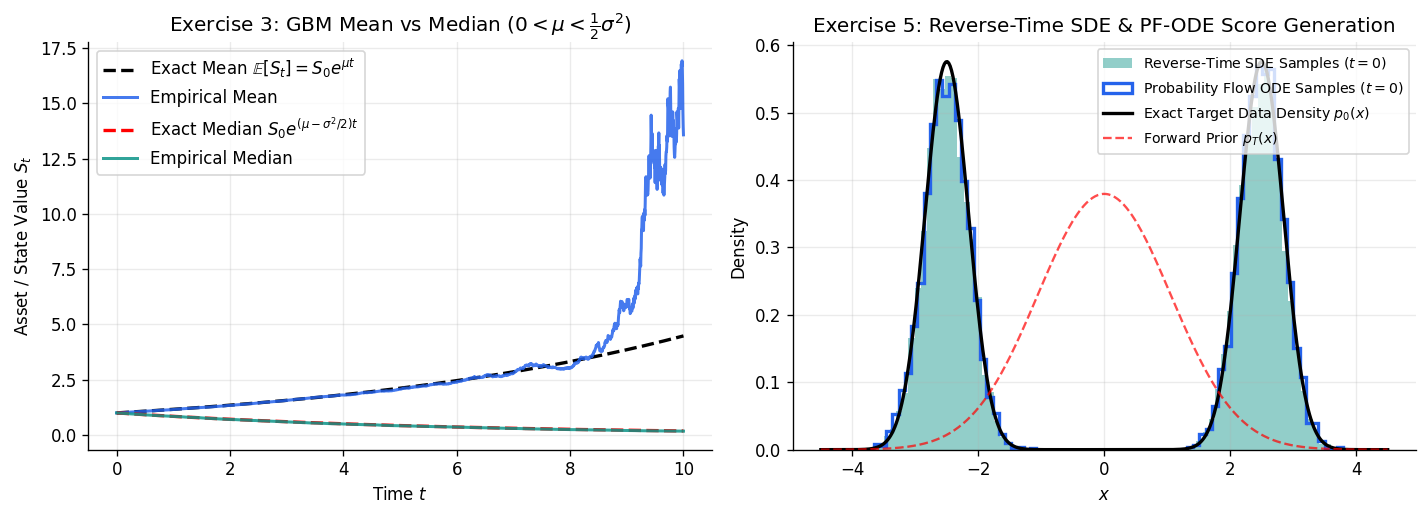

In [5]:
# Part A: Verify Exercise 4 (SGD vs Continuous SDE on quadratic objective)
lam_sgd = 1.2
sigma0_sgd = 1.5
eta_sgd = 0.04
T_sgd = 4.0
n_steps_sgd = int(T_sgd / eta_sgd)
n_runs_sgd = 5000

theta_sgd = np.full(n_runs_sgd, 2.0)
for _ in range(n_steps_sgd):
    grad_noisy = lam_sgd * theta_sgd + sigma0_sgd * np.random.randn(n_runs_sgd)
    theta_sgd = theta_sgd - eta_sgd * grad_noisy

sde_exact_var = (eta_sgd * sigma0_sgd ** 2) / (2.0 * lam_sgd) * (1.0 - np.exp(-2.0 * lam_sgd * T_sgd))
print("Exercise 4 (SGD vs Continuous Diffusion Limit at t = 4.0):")
print(f"  Empirical SGD Variance = {np.var(theta_sgd):.5f} | Continuous SDE Variance = {sde_exact_var:.5f}")

# Part B: Exercise 5 (Reverse-Time SDE & Probability Flow ODE on 1D Gaussian Mixture)
m1, m2 = -2.5, 2.5
w1, w2 = 0.5, 0.5
v0 = 0.12
T_diff = 4.0
n_steps_diff = 1000
dt_diff = T_diff / n_steps_diff

def exact_gmm_density_and_score(x, t):
    '''Compute exact marginal density p_t(x) and score d/dx log p_t(x) at time t.'''
    alpha_t = np.exp(-0.5 * t)
    v_t = v0 * np.exp(-t) + (1.0 - np.exp(-t))
    
    mu1_t = m1 * alpha_t
    mu2_t = m2 * alpha_t
    
    p1 = (w1 / np.sqrt(2.0 * np.pi * v_t)) * np.exp(-0.5 * ((x - mu1_t) ** 2) / v_t)
    p2 = (w2 / np.sqrt(2.0 * np.pi * v_t)) * np.exp(-0.5 * ((x - mu2_t) ** 2) / v_t)
    p_total = p1 + p2 + 1e-15
    
    grad_p1 = -((x - mu1_t) / v_t) * p1
    grad_p2 = -((x - mu2_t) / v_t) * p2
    score = (grad_p1 + grad_p2) / p_total
    return p_total, score

# Sample terminal prior at t = T_diff
n_gen = 8000
_, _ = exact_gmm_density_and_score(0.0, T_diff)
alpha_T = np.exp(-0.5 * T_diff)
v_T = v0 * np.exp(-T_diff) + (1.0 - np.exp(-T_diff))
comp_choice = (np.random.rand(n_gen) < w1)
x_init_T = np.where(comp_choice, m1 * alpha_T, m2 * alpha_T) + np.sqrt(v_T) * np.random.randn(n_gen)

x_rev_sde = x_init_T.copy()
x_pf_ode = x_init_T.copy()

# Integrate backwards from t = T_diff to t = 0
for step in range(n_steps_diff):
    t_curr = T_diff - step * dt_diff
    _, score_sde = exact_gmm_density_and_score(x_rev_sde, t_curr)
    _, score_ode = exact_gmm_density_and_score(x_pf_ode, t_curr)
    
    # Reverse-Time SDE step
    x_rev_sde = x_rev_sde + (0.5 * x_rev_sde + score_sde) * dt_diff + np.sqrt(dt_diff) * np.random.randn(n_gen)
    # Probability Flow ODE step
    x_pf_ode = x_pf_ode + (0.5 * x_pf_ode + 0.5 * score_ode) * dt_diff

# Plot GBM Paradox (Left) and Reverse-Time SDE / PF-ODE Generation (Right)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].plot(t_gbm, exact_mean_S, "k--", lw=2, label=r"Exact Mean $\mathbb{E}[S_t] = S_0 e^{\mu t}$")
axes[0].plot(t_gbm, emp_mean_S, color="#2563eb", lw=1.8, alpha=0.85, label="Empirical Mean")
axes[0].plot(t_gbm, exact_median_S, "r--", lw=2, label=r"Exact Median $S_0 e^{(\mu - \sigma^2/2)t}$")
axes[0].plot(t_gbm, emp_median_S, color="#0d9488", lw=1.8, alpha=0.85, label="Empirical Median")
axes[0].set_title(r"Exercise 3: GBM Mean vs Median ($0 < \mu < \frac{1}{2}\sigma^2$)")
axes[0].set_xlabel("Time $t$")
axes[0].set_ylabel("Asset / State Value $S_t$")
axes[0].legend(loc="upper left")

x_grid = np.linspace(-4.5, 4.5, 400)
p0_exact, _ = exact_gmm_density_and_score(x_grid, 0.0)
pT_exact, _ = exact_gmm_density_and_score(x_grid, T_diff)

axes[1].hist(x_rev_sde, bins=75, density=True, alpha=0.45, color="#0d9488", label="Reverse-Time SDE Samples ($t=0$)")
axes[1].hist(x_pf_ode, bins=75, density=True, histtype="step", lw=2.0, color="#2563eb", label="Probability Flow ODE Samples ($t=0$)")
axes[1].plot(x_grid, p0_exact, "k-", lw=2.0, label="Exact Target Data Density $p_0(x)$")
axes[1].plot(x_grid, pT_exact, "r--", lw=1.4, alpha=0.7, label="Forward Prior $p_T(x)$")
axes[1].set_title("Exercise 5: Reverse-Time SDE & PF-ODE Score Generation")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()